In [1]:
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt

In [2]:
# Load model
BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path="face_landmarker.task"),
    running_mode=VisionRunningMode.IMAGE,
    num_faces=1
)

# Load image
image = mp.Image.create_from_file("data/test_image.png")

# Detect landmarks
with FaceLandmarker.create_from_options(options) as landmarker:
    result = landmarker.detect(image)

W0000 00:00:1793709964.198256   98349 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1793709964.236887   98353 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793709964.270709   98353 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Number of landmarks: 478


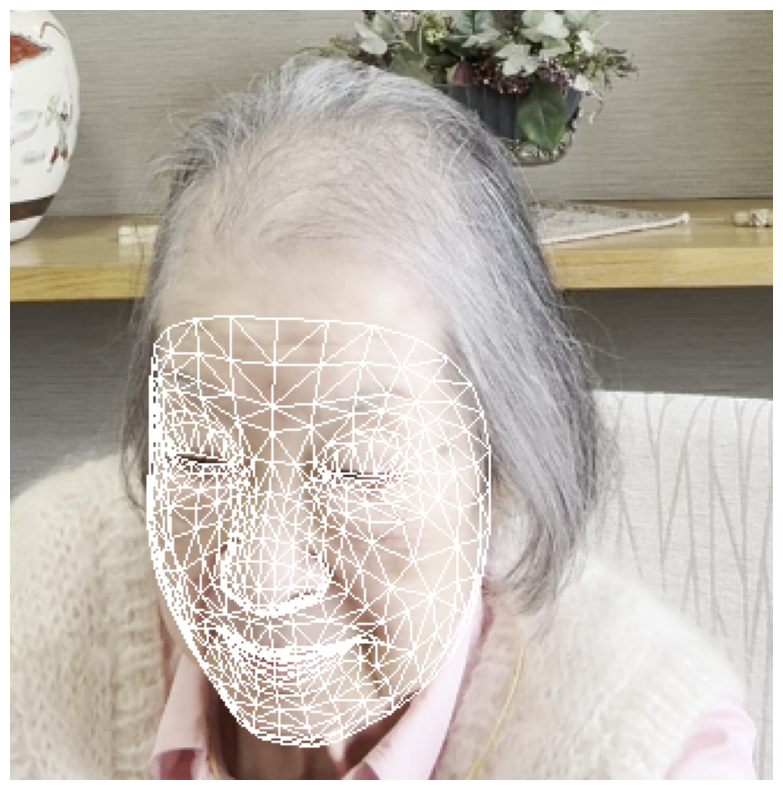

In [4]:
# Visualize
annotated_image = image.numpy_view().copy()
height, width, _ = annotated_image.shape

if result.face_landmarks:
    landmarks = result.face_landmarks[0]

    connections = (mp.tasks.vision.FaceLandmarksConnections.FACE_LANDMARKS_TESSELATION)

    for connection in connections:
        start = landmarks[connection.start]
        end = landmarks[connection.end]

        p1 = (int(start.x * width), int(start.y * height))
        p2 = (int(end.x * width), int(end.y * height))

        cv2.line(annotated_image, p1, p2, (0, 255, 0), 1)

    print(f"Number of landmarks: {len(landmarks)}")

plt.figure(figsize=(10, 10))
plt.imshow(annotated_image)
plt.axis("off")
plt.show()